# 10 · Graph expansion of the first stage, with leakage controls (Phase 5, tasks 5.4–5.7)

The starting point is Qwen3-Embedding-8B's top 100 over the full corpus (notebook 09): recall@100 64.0% on test. 315 test positives fall outside it, and 151 of those are reachable through an allowed citer.

- **GRIT-style expansion (5.6).** Keep the list length K = 100. Take the top *t* results as seeds, and replace the bottom fraction *b* with the seeds' strongest co-citation neighbours over the leakage-controlled graph (all rules R1–R5, conservative dates).
  - Neighbour scores are either raw co-citation counts or counts normalized by the square root of the neighbour's degree.
  - *t*, *b* and the normalization are chosen on **dev only** (48 queries), by recall@100.
- **Controls, with the chosen setting fixed:**
  - **random graph (5.5):** the same expansion on 5 degree-preserving rewirings (Curveball) of the pool citers;
  - **kNN graph:** the same expansion over a Qwen3 document kNN graph, with no citations involved;
  - **leakage ablations and canary (5.4):** each rule switched off in turn, and the query's own references added on purpose.
- **LADR-style variant (5.7).** BM25 top-100 seeds plus adaptive exploration of the Qwen3 kNN graph, scored by Qwen3. LADR is an efficiency method, so the question is how close it gets to exhaustive Qwen3 retrieval while scoring only part of the corpus.

Only the bottom of each list changes, so nDCG@10 and recall@k for k up to 100(1 − b) are unchanged. **Recall@100 is the metric here.** Differences from the Qwen3 baseline get paired bootstrap CIs and Holm-corrected Wilcoxon tests (test split). End-to-end reranking of the expanded lists is notebook 11.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

RESEARCH = Path.cwd().parent if Path.cwd().name == "v2" else Path.cwd()
sys.path.insert(0, str(RESEARCH))

import numpy as np
import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

from src.figures import save, setup_style
setup_style()

In [2]:
K = 100
GRID_T = [5, 10, 20, 50]
GRID_B = [0.1, 0.2, 0.3, 0.5]
GRID_NORM = ["count", "cosine"]
RANDOM_GRAPH_SEEDS = [0, 1, 2, 3, 4]
KNN_K = [8, 16, 32]      # LADR graph degree, chosen on dev; the GRIT kNN control uses 16
LADR_SEEDS = 100         # BM25 top-100 seeds

In [3]:
import json

from src.pipeline_v2 import EMB_CACHE
from src.rankers_v2 import EmbeddingCache
from src.retrieval import dense_matrix, load_phase5

S = load_phase5(RESEARCH)
g, labels, qids, idx, masks, pos_idx = S["g"], S["labels"], S["qids"], S["idx"], S["masks"], S["pos_idx"]
dev_q = [q for q in qids if labels[q]["split"] == "dev"]
test_q = [q for q in qids if labels[q]["split"] == "test"]

def load_orders(method):
    with (RESEARCH / "v2" / "runs_corpus" / "stage1" / f"{method}.jsonl").open() as f:
        return {r["pi_id"]: np.array([idx[d] for d in r["top100"]]) for r in map(json.loads, f)}

top_qwen, top_bm25 = load_orders("qwen"), load_orders("bm25")
qwen = dense_matrix("qwen", S["doc_texts"], S["query_texts"], EMB_CACHE / S["tag"])  # cached: no model calls
qrow = {q: i for i, q in enumerate(qids)}
doc_emb = EmbeddingCache("qwen", EMB_CACHE / S["tag"]).get(S["doc_texts"])
pool_rows = ~g.is_query & ~g.is_query_dup

def recall_at(order, q):
    return float(np.isin(pos_idx[q], order[:K]).mean())

base = {q: recall_at(top_qwen[q], q) for q in qids}
print(f"Qwen3 recall@100: dev {np.mean([base[q] for q in dev_q]) * 100:.1f}, test {np.mean([base[q] for q in test_q]) * 100:.1f}")

Qwen3 recall@100: dev 67.4, test 64.0


### GRIT-style expansion: dev grid

In [4]:
from src.cograph import Rules
from src.expansion import cocitation_scores, grit_expand

def run_grit(graph, queries, t, b, norm, rules=Rules(), restrict=None):
    """Per-query recall@100 after expansion, plus the added docs. `restrict` limits citer rows (e.g. pool rows)."""
    out = {}
    for q in queries:
        mask = graph.allowed(q, labels[q]["date"], rules)
        if restrict is not None:
            mask &= restrict | (rules.canary & (np.arange(len(mask)) == graph.row_of(q)))
        top = top_qwen[q]
        gs = cocitation_scores(graph, top[:t], mask, norm)
        new, added = grit_expand(top, t, b, gs, masks[q].copy(), qwen[qrow[q]])
        out[q] = {"recall": recall_at(new, q), "added": added, "order": new}
    return out

grid = []
for norm in GRID_NORM:
    for t in GRID_T:
        for b in GRID_B:
            res = run_grit(g, dev_q, t, b, norm)
            grid.append({"norm": norm, "t": t, "b": b,
                         "recall@100": np.mean([res[q]["recall"] for q in dev_q]) * 100})
grid = pd.DataFrame(grid)
grid["gain"] = grid["recall@100"] - np.mean([base[q] for q in dev_q]) * 100
best = grid.sort_values(["recall@100", "b", "t"], ascending=[False, True, True]).iloc[0]
T, B, NORM = int(best.t), float(best.b), best.norm
print(f"chosen on dev: t = {T}, b = {B}, norm = {NORM} (dev recall@100 {best['recall@100']:.1f}, gain {best.gain:+.1f})")
grid.pivot_table(index=["norm", "t"], columns="b", values="gain").round(1)

chosen on dev: t = 5, b = 0.1, norm = count (dev recall@100 69.1, gain +1.7)


b          0.1  0.2  0.3  0.5
norm   t                     
cosine 5   0.3  0.9  0.1 -2.2
       10  0.4 -0.1 -1.5 -4.2
       20  0.6 -0.1 -1.8 -3.9
       50 -0.3 -0.7 -2.9 -5.2
count  5   1.7  1.1 -0.0 -1.9
       10  1.0  1.1 -0.1 -2.4
       20  0.5  0.8 -1.4 -3.5
       50  0.4 -0.3 -1.8 -4.0

### Test: expansion and its controls (fixed dev setting)

In [5]:
import time

from dataclasses import replace

from src.cograph import curveball
from src.corpus import CITERS, citer_pool
from src.cograph import day
from src.expansion import knn_graph, knn_scores

results = {"Qwen3 (no expansion)": {q: {"recall": base[q], "added": np.array([], int)} for q in test_q}}
results["Co-citation graph (all rules)"] = run_grit(g, test_q, T, B, NORM)

t0 = time.time()
for s in RANDOM_GRAPH_SEEDS:
    rg = curveball(g, np.flatnonzero(pool_rows), np.random.default_rng(s))
    results[f"Random graph, seed {s}"] = run_grit(rg, test_q, T, B, NORM)
print(f"{len(RANDOM_GRAPH_SEEDS)} random graphs in {time.time() - t0:.0f} s")

knn_idx, knn_sim = knn_graph(doc_emb, 16)
res = {}
for q in test_q:
    top = top_qwen[q]
    ks = knn_scores(knn_idx, knn_sim, top[:T], len(S["doc_ids"]))
    new, added = grit_expand(top, T, B, ks, masks[q].copy(), qwen[qrow[q]])
    res[q] = {"recall": recall_at(new, q), "added": added}
results["kNN graph (Qwen3, k = 16)"] = res

5 random graphs in 4 s


In [6]:
# Leakage ablations: the same expansion with one rule relaxed, and the canary.
citer_groups = json.loads((RESEARCH / "v2" / "corpus" / "citer_groups.json").read_text())
pool = citer_pool([json.loads(p.read_text()) for p in sorted(CITERS.glob("*.json"))])
member_dates = {}
for c in g.citer_ids:
    members = citer_groups.get(c, [c])
    dates = [(pool.get(m) or S["works"].get(m) or {}).get("publication_date") for m in members]
    dates = [d for d in dates if d]
    member_dates[c] = max(dates) if dates else None
g_recorded = replace(g, citer_day=np.array([day(member_dates[c]) for c in g.citer_ids], dtype=np.int64))

ABLATIONS = {
    "R3 off: keep query duplicates": (g, Rules(drop_query_dups=False)),
    "R4 with recorded dates": (g_recorded, Rules()),
    "R4 off: allow later citers": (g, Rules(temporal=False)),
    "R5 off: allow other query records": (g, Rules(drop_query_records=False)),
    "Canary: add the query's own references": (g, Rules(canary=True)),
}
for name, (graph, rules) in ABLATIONS.items():
    results[name] = run_grit(graph, test_q, T, B, NORM, rules=rules)

### LADR-style adaptive exploration (5.7)

In [7]:
from src.expansion import ladr_adaptive

ladr_rows = []
knn_by_k = {k: knn_graph(doc_emb, k)[0] for k in KNN_K}
for k, knn in knn_by_k.items():
    for split, qs in (("dev", dev_q), ("test", test_q)):
        for q in qs:
            top, n_scored = ladr_adaptive(top_bm25[q][:LADR_SEEDS], knn, qwen[qrow[q]], masks[q], depth=K)
            ladr_rows.append({"k": k, "split": split, "pi_id": q, "recall": recall_at(top, q),
                              "scored": n_scored, "candidates": int(masks[q].sum())})
ladr = pd.DataFrame(ladr_rows)
ladr_tab = ladr.groupby(["split", "k"]).agg(recall=("recall", "mean"), scored=("scored", "median"),
                                            candidates=("candidates", "median"))
ladr_tab["recall"] *= 100
ladr_tab["scored_share"] = ladr_tab.scored / ladr_tab.candidates
K_LADR = int(ladr_tab.loc["dev"].recall.idxmax())
print(f"LADR graph degree chosen on dev: k = {K_LADR}")
results[f"LADR (BM25 seeds + kNN k = {K_LADR})"] = {
    r.pi_id: {"recall": r.recall, "added": np.array([], int)} for r in ladr[(ladr.k == K_LADR) & (ladr.split == "test")].itertuples()}
ladr_tab.round(3)

LADR graph degree chosen on dev: k = 32


recall  scored  candidates  scored_share
split k                                           
dev   8   63.620   623.5     11313.0         0.055
      16  66.196   990.0     11313.0         0.088
      32  66.369  1507.5     11313.0         0.133
test  8   58.098   619.0     11253.0         0.055
      16  60.607   936.5     11253.0         0.083
      32  62.294  1410.5     11253.0         0.125

### Test table: recall@100 and paired differences from Qwen3

In [8]:
from scipy.stats import wilcoxon

from src.stats_v2 import boot_ci, holm

rng = np.random.default_rng(42)
b0 = np.array([base[q] for q in test_q])
rows = []
for name, res in results.items():
    x = np.array([res[q]["recall"] for q in test_q])
    d = x - b0
    lo, hi = boot_ci(x, rng)
    dlo, dhi = boot_ci(d, rng)
    p = wilcoxon(x, b0).pvalue if np.any(d != 0) else np.nan
    rows.append({"condition": name, "recall@100": x.mean() * 100, "ci": f"[{lo * 100:.1f}, {hi * 100:.1f}]",
                 "diff": d.mean() * 100, "diff_ci": f"[{dlo * 100:+.1f}, {dhi * 100:+.1f}]",
                 "queries_up": int((d > 0).sum()), "queries_down": int((d < 0).sum()), "p": p})
tab = pd.DataFrame(rows)
has_p = tab.p.notna()
tab.loc[has_p, "p_holm"] = holm(tab.loc[has_p, "p"].tolist())
rand = tab[tab.condition.str.startswith("Random graph")]
print(f"random graphs: mean recall@100 {rand['recall@100'].mean():.1f} (range {rand['recall@100'].min():.1f}–{rand['recall@100'].max():.1f})")
tab.round({"recall@100": 1, "diff": 2})

random graphs: mean recall@100 63.3 (range 63.1–63.5)


,condition,recall@100,ci,diff,diff_ci,queries_up,queries_down,p,p_holm
0,Qwen3 (no expansion),64.0,"[58.8, 69.3]",0.00,"[+0.0, +0.0]",0,0,NaN,NaN
1,Co-citation graph (all rules),64.9,"[59.8, 70.0]",0.83,"[-0.4, +2.1]",14,7,0.321299,1.000000
2,"Random graph, seed 0",63.3,"[57.9, 68.5]",-0.76,"[-1.6, +0.0]",3,9,0.059346,0.593464
3,"Random graph, seed 1",63.3,"[58.0, 68.4]",-0.75,"[-1.7, +0.1]",5,10,0.068808,0.619269
4,"Random graph, seed 2",63.2,"[57.8, 68.4]",-0.88,"[-1.8, -0.1]",4,10,0.021748,0.260980
5,"Random graph, seed 3",63.1,"[57.8, 68.3]",-0.94,"[-1.8, -0.1]",3,10,0.025062,0.275680
6,"Random graph, seed 4",63.5,"[58.2, 68.8]",-0.52,"[-1.5, +0.5]",5,9,0.220330,1.000000
7,"kNN graph (Qwen3, k = 16)",64.3,"[59.0, 69.5]",0.27,"[-0.6, +1.3]",5,4,0.812542,1.000000
8,R3 off: keep query duplicates,64.9,"[59.8, 69.8]",0.83,"[-0.3, +2.0]",14,7,0.321299,1.000000
9,R4 with recorded dates,65.0,"[59.8, 70.1]",0.98,"[-0.3, +2.3]",17,8,0.281411,1.000000


### Attribution (5.9, first stage)

Among the positives in the expanded test lists, how many entered through the graph, and what share of the 151 reachable-but-missed positives the expansion recovered.

In [9]:
main = results["Co-citation graph (all rules)"]
found = sum(int(np.isin(pos_idx[q], main[q]["order"]).sum()) for q in test_q)
via_graph = sum(int(np.isin(main[q]["added"], pos_idx[q]).sum()) for q in test_q)
missed_before = sum(int((~np.isin(pos_idx[q], top_qwen[q])).sum()) for q in test_q)
print(f"positives in the expanded top 100: {found}; entered through the graph: {via_graph} ({via_graph / max(found, 1):.1%})")
print(f"positives outside Qwen3's top 100: {missed_before}; recovered by the expansion: {via_graph} ({via_graph / missed_before:.1%})")
removed = sum(int(np.isin(pos_idx[q], np.setdiff1d(top_qwen[q], main[q]["order"])).sum()) for q in test_q)
print(f"positives pushed out of the list by the replacement: {removed}")

positives in the expanded top 100: 548; entered through the graph: 20 (3.6%)
positives outside Qwen3's top 100: 315; recovered by the expansion: 20 (6.3%)
positives pushed out of the list by the replacement: 8


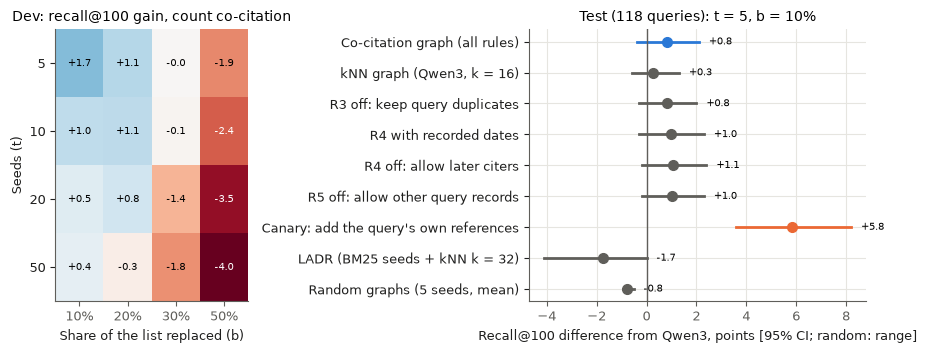

In [10]:
import matplotlib.pyplot as plt

from src.figures import INK_2, SLOTS

fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.6), gridspec_kw={"width_ratios": [0.8, 1.4]})
ax = axes[0]
hm = grid[grid.norm == NORM].pivot(index="t", columns="b", values="gain")
lim = np.abs(hm.values).max()
im = ax.imshow(hm.values, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        ax.text(j, i, f"{hm.values[i, j]:+.1f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(hm.values[i, j]) > 0.6 * lim else "black")
ax.set_xticks(range(hm.shape[1]), [f"{int(b * 100)}%" for b in hm.columns])
ax.set_yticks(range(hm.shape[0]), hm.index)
ax.set_xlabel("Share of the list replaced (b)")
ax.set_ylabel("Seeds (t)")
ax.set_title(f"Dev: recall@100 gain, {NORM} co-citation")
ax.grid(False)

ax = axes[1]
show = [c for c in tab.condition if not c.startswith("Random graph") and c != "Qwen3 (no expansion)"]
rows_plot = [tab.set_index("condition").loc[c] for c in show]
rand_mean = rand["diff"].mean()
names = show + ["Random graphs (5 seeds, mean)"]
diffs = [r["diff"] for r in rows_plot] + [rand_mean]
cis = [tuple(float(v) for v in r["diff_ci"].strip("[]").split(", ")) for r in rows_plot] + [(rand["diff"].min(), rand["diff"].max())]
colors = [SLOTS[0] if n.startswith("Co-citation") else SLOTS[1] if n.startswith("Canary") else INK_2 for n in names]
for i, (dv, (lo, hi), c) in enumerate(zip(diffs, cis, colors)):
    ax.plot([lo, hi], [i, i], color=c, lw=2)
    ax.plot(dv, i, "o", color=c)
    ax.text(max(hi, dv) + 0.4, i, f"{dv:+.1f}", va="center", fontsize=7.5)
ax.axvline(0, color=INK_2, lw=1)
ax.set_yticks(range(len(names)), names)
ax.invert_yaxis()
ax.set_xlabel("Recall@100 difference from Qwen3, points [95% CI; random: range]")
ax.set_title(f"Test (118 queries): t = {T}, b = {int(B * 100)}%")
fig.tight_layout()
save(fig, "10_graph_expansion")
plt.show()

### Findings

- **Dev choice.** Raw co-citation counts, t = 5 seeds, b = 10% of the list replaced: +1.7 points recall@100 on dev (67.4 → 69.1). Replacing more of the list hurts on dev, up to −4.0 (count) and −5.2 (cosine) at b = 50%. Count beats cosine normalization in 14 of 16 cells.
- **Test: the expansion does not help significantly.** The co-citation graph under all leakage rules gives **+0.8 points recall@100 [−0.4, +2.1]** (64.0 → 64.9). It improves 14 queries and worsens 7, and the Wilcoxon test is not significant (p = 0.32, Holm 1.0).
- **Controls behave as they should.**
  - **Canary** (the query's own references added): **+5.8 [+3.6, +8.2]**, Holm p = 1.6e-4. The pipeline does pick up citation signal when it is there; the gain is bounded by the 10 replaced slots.
  - **Random graphs** (5 degree-preserving rewirings): −0.5 to −0.9 (mean −0.8). Filling the bottom with random neighbours loses positives. So the real graph is about 1.6 points better than a random one, but not better than doing nothing.
  - **kNN graph** (Qwen3 neighbours, no citations): +0.3 [−0.6, +1.3].
- **Leakage ablations at this setting.** Relaxing a rule adds only a little: R3 off +0.8 (unchanged), R4 with recorded dates +1.0, R4 off +1.1, R5 off +1.0. With only 10 slots per query, a leak can add at most a few positives. Notebook 08 showed the reachability gaps are larger (54.7% → 55.1–70.1%, depending on the rule).
- **LADR-style exploration (5.7).** With BM25 seeds and the kNN graph (k = 32, chosen on dev), it reaches 62.3% recall@100 on test against 64.0% for exhaustive Qwen3 (−1.7 [−4.1, −0.0]). It scores a median of 1,410 of 11,253 candidates (12.5%); with k = 16 it reaches 60.6% scoring 8.3%. As expected for an efficiency method, it approximates exhaustive dense retrieval and does not exceed it.
- **Attribution (first stage).**
  - Of the 548 positives in the expanded test lists, **20 (3.6%) entered through the graph**: 6.3% of the 315 that Qwen3 had missed.
  - The replacement pushed 8 positives out.
  - At most 151 of the missed positives were reachable at all (notebook 09), and the co-citation neighbours of the top-5 seeds rarely include them.
- **Conclusion so far.** Once the graph is leakage-controlled and the first stage is a strong dense model, co-citation expansion adds at most about a point of recall@100, and not significantly. Leaky versions look slightly better, and the canary confirms the machinery works. Notebook 11 checks whether reranking the expanded lists changes this end to end.
- **Figure.** `10_graph_expansion`.
